# P1 — Predicción de viajes iniciados por estación (MiBici)

**Pregunta:** ¿Cuántos viajes se iniciarán en una estación de MiBici durante el día siguiente?

**Enfoque:** regresión supervisada con una observación por estación y día.  
**Datos:** viajes de 2024 y 2025, consolidados en un CSV.  
**Objetivo del notebook:** análisis de calidad, preparación de variables históricas, evaluación del baseline y Random Forest y registro de los dos modelos en MLflow local.

**Reproducción:** coloca `mibici_2024_2025.csv` en `data/raw/`, instala las dependencias y ejecuta las celdas en orden. No se requiere indicar una ruta personal; el CSV no debe subirse a GitHub.

**Ejecución independiente del notebook:** para reproducir los experimentos directamente desde código del repositorio, se incluye `MiBici/modeling/train_p1.py`. Utiliza los mismos cortes temporales, variables, hiperparámetros, métricas y experimento MLflow.

## 1. Configuración y fuente de datos

Se utiliza únicamente `Viaje_Id` (verificación de duplicados), `Inicio_del_viaje` (fecha del inicio) y `Origen_Id` (estación). No se cargan ni publican `Usuario_Id`, género o año de nacimiento.

**Fuente original declarada:** [Datos abiertos de MiBici](https://www.mibici.net/es/datos-abiertos/). Para reproducir la consolidación a partir de archivos mensuales todavía se requiere implementar la ingesta compartida del equipo.

In [1]:
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Localizar la raíz del repositorio, independientemente del directorio del notebook.
current_dir = Path.cwd()
project_root = next(
  (
    path for path in [current_dir, *current_dir.parents]
    if (path / "pyproject.toml").exists()
  ),
  None
)

if project_root is None:
  raise FileNotFoundError("Abre el notebook desde el repositorio que contiene pyproject.toml.")

csv_path = project_root / "data" / "raw" / "mibici_2024_2025.csv"
if not csv_path.is_file():
  raise FileNotFoundError(
    "Falta data/raw/mibici_2024_2025.csv."
  )

## 2. Validación y agregación inicial

El archivo se procesa por bloques para reducir el uso de memoria. Se verifican fechas, identificadores, duplicados de `Viaje_Id`, cobertura temporal y conteos por estación y día. Se comprueba que los conteos agregados conserven la totalidad de los viajes.

**Alcance de la validación:** se comprueba que los IDs de origen sean enteros positivos, pero no que cada ID corresponda a una estación existente en el catálogo oficial histórico de MiBici.

In [2]:
ids_por_bloque = []
conteos_diarios = Counter()
meses = Counter()
dias_registrados = set()
estaciones = set()
total_viajes = 0
fechas_invalidas = 0
ids_viaje_invalidos = 0
origenes_invalidos = 0
fuera_rango = 0

for chunk in pd.read_csv(
  csv_path,
  usecols=["Viaje_Id", "Inicio_del_viaje", "Origen_Id"],
  chunksize=200_000
):
  total_viajes += len(chunk)
  fechas = pd.to_datetime(chunk["Inicio_del_viaje"], errors="coerce")
  ids = pd.to_numeric(chunk["Viaje_Id"], errors="coerce")
  origenes = pd.to_numeric(chunk["Origen_Id"], errors="coerce")

  ids_validos = ids.notna() & (ids > 0) & (ids % 1 == 0)
  origenes_validos = origenes.notna() & (origenes > 0) & (origenes % 1 == 0)
  fechas_validas = fechas.notna()

  fechas_invalidas += int((~fechas_validas).sum())
  ids_viaje_invalidos += int((~ids_validos).sum())
  origenes_invalidos += int((~origenes_validos).sum())
  fuera_rango += int((fechas_validas & ~fechas.between("2024-01-01", "2025-12-31 23:59:59")).sum())
  ids_por_bloque.append(ids[ids_validos].to_numpy(dtype=np.int64))

  fechas_ok = fechas[fechas_validas]
  meses.update(fechas_ok.dt.to_period("M").astype(str).value_counts().to_dict())
  dias_registrados.update(fechas_ok.dt.normalize().unique())
  estaciones.update(origenes[origenes_validos].astype("int64").unique())

  filas_validas = fechas_validas & origenes_validos
  datos_validos = pd.DataFrame({
    "estacion_id": origenes[filas_validas].astype("int64"),
    "fecha": fechas[filas_validas].dt.normalize()
  })
  conteos_diarios.update(
    datos_validos.groupby(["estacion_id", "fecha"]).size().to_dict()
  )

ids_ordenados = np.concatenate(ids_por_bloque)
ids_ordenados.sort()
viajes_duplicados = int(np.count_nonzero(ids_ordenados[1:] == ids_ordenados[:-1]))
del ids_ordenados, ids_por_bloque

dias_esperados = pd.date_range("2024-01-01", "2025-12-31", freq="D")
dias_observados = pd.DatetimeIndex(dias_registrados)
dias_faltantes = dias_esperados.difference(dias_observados)

resumen_calidad = pd.Series({
  "Viajes en el CSV": total_viajes,
  "Meses presentes": len(meses),
  "Días registrados": len(dias_observados),
  "Días esperados": len(dias_esperados),
  "Días faltantes globalmente": len(dias_faltantes),
  "Estaciones de origen distintas": len(estaciones),
  "Fechas inválidas": fechas_invalidas,
  "IDs de viaje inválidos": ids_viaje_invalidos,
  "Viajes duplicados por ID": viajes_duplicados,
  "IDs de origen inválidos": origenes_invalidos,
  "Fechas fuera de 2024-2025": fuera_rango
})
display(resumen_calidad.to_frame("Resultado"))

# Continuar solo con el dataset limpio que se verificó para este experimento.
assert fechas_invalidas == 0 and ids_viaje_invalidos == 0
assert origenes_invalidos == 0 and viajes_duplicados == 0
assert fuera_rango == 0 and len(dias_faltantes) == 0

df_diario = pd.DataFrame(
  [(estacion, fecha, cantidad) for (estacion, fecha), cantidad in conteos_diarios.items()],
  columns=["estacion_id", "fecha", "viajes_iniciados"]
).sort_values(["estacion_id", "fecha"]).reset_index(drop=True)

assert int(df_diario["viajes_iniciados"].sum()) == total_viajes
print("Filas estación-día con viajes registrados:", len(df_diario))
print("Viajes conservados:", int(df_diario["viajes_iniciados"].sum()))
display(df_diario.head(5))

,Resultado
Viajes en el CSV,9177953
Meses presentes,24
Días registrados,731
Días esperados,731
Días faltantes globalmente,0
Estaciones de origen distintas,373
Fechas inválidas,0
IDs de viaje inválidos,0
Viajes duplicados por ID,0
IDs de origen inválidos,0


Filas estación-día con viajes registrados: 265105
Viajes conservados: 9177953


,estacion_id,fecha,viajes_iniciados
0,2,2024-01-01,23
1,2,2024-01-02,98
2,2,2024-01-03,103
3,2,2024-01-04,99
4,2,2024-01-05,101


## 3. Panel diario y supuesto de días sin registros

Para cada estación se genera una fecha por día **entre su primer y último viaje observado**. Los días intermedios sin registros se completan con cero viajes, manteniendo `sin_viajes_registrados` como marca de auditoría.

**Limitación:** un cero imputado no prueba que la estación estuviera operativa. Esta regla es provisional y debe verificarse con los periodos de operación o el catálogo histórico de estaciones. No se generan ceros anteriores al primer viaje ni posteriores al último viaje de una estación.

In [3]:
rangos = df_diario.groupby("estacion_id")["fecha"].agg(["min", "max"])
panel_fechas = pd.concat(
  [
    pd.DataFrame({
      "estacion_id": estacion_id,
      "fecha": pd.date_range(row["min"], row["max"], freq="D")
    })
    for estacion_id, row in rangos.iterrows()
  ],
  ignore_index=True
)

df_p1 = panel_fechas.merge(
  df_diario,
  on=["estacion_id", "fecha"],
  how="left",
  validate="one_to_one"
)
df_p1["sin_viajes_registrados"] = df_p1["viajes_iniciados"].isna()
df_p1["viajes_iniciados"] = df_p1["viajes_iniciados"].fillna(0).astype(int)
df_p1 = df_p1.sort_values(["estacion_id", "fecha"]).reset_index(drop=True)

resumen_estaciones = df_p1.groupby("estacion_id")["sin_viajes_registrados"].sum()
print("Filas estación-día observadas:", len(df_diario))
print("Filas del panel diario:", len(df_p1))
print("Días completados con cero:", int(df_p1["sin_viajes_registrados"].sum()))
print("Estaciones con al menos un día completado:", int((resumen_estaciones > 0).sum()))
assert df_p1["viajes_iniciados"].sum() == total_viajes
assert df_p1["sin_viajes_registrados"].sum() == len(df_p1) - len(df_diario)

Filas estación-día observadas: 265105
Filas del panel diario: 265873
Días completados con cero: 768
Estaciones con al menos un día completado: 111


## 4. Variables para predecir el día siguiente

Para cada estación y fecha objetivo se usan variables conocidas antes de ese día: día de la semana, mes, fin de semana, viajes de ayer, viajes del mismo día de la semana anterior y promedio de los siete días previos. El indicador `sin_viajes_registrados` **no se utiliza como predictor**, ya que se calcula con la observación del día objetivo.

La unidad de predicción es **una estación en un día**; la variable objetivo `viajes_iniciados` es un entero no negativo.

In [4]:
df_features = df_p1.copy().sort_values(["estacion_id", "fecha"]).reset_index(drop=True)
df_features["dia_semana"] = df_features["fecha"].dt.dayofweek
df_features["mes"] = df_features["fecha"].dt.month
df_features["es_fin_semana"] = (df_features["dia_semana"] >= 5).astype(int)

grupo = df_features.groupby("estacion_id")["viajes_iniciados"]
df_features["viajes_lag_1"] = grupo.shift(1)
df_features["viajes_lag_7"] = grupo.shift(7)
df_features["promedio_7d"] = grupo.transform(
  lambda serie: serie.shift(1).rolling(window=7, min_periods=7).mean()
)

columnas_features = [
  "estacion_id", "dia_semana", "mes", "es_fin_semana",
  "viajes_lag_1", "viajes_lag_7", "promedio_7d"
]
df_modelo = df_features.dropna(
  subset=["viajes_lag_1", "viajes_lag_7", "promedio_7d"]
).copy()

print("Filas del panel:", len(df_features))
print("Filas listas para modelado:", len(df_modelo))
print("Filas excluidas sin 7 días previos:", len(df_features) - len(df_modelo))
assert not df_modelo[columnas_features].isna().any().any()

Filas del panel: 265873
Filas listas para modelado: 263262
Filas excluidas sin 7 días previos: 2611


## 5. División cronológica y prevención de fuga temporal

- **Entrenamiento:** enero de 2024 a junio de 2025 (las primeras 7 observaciones por estación se excluyen por falta de historial).
- **Validación:** julio a septiembre de 2025, para comparar el baseline y el modelo candidato.
- **Prueba reservada:** octubre a diciembre de 2025. **No se usa para elegir el modelo en este notebook.**

Las variables *lag* de validación pueden tomar valores reales de días anteriores, incluso cuando esos días pertenecen a otro conjunto: corresponde a un escenario de **pronóstico diario actualizado**, no a un pronóstico multimes realizado con antelación.

In [5]:
train = df_modelo[df_modelo["fecha"] < "2025-07-01"].copy()
val = df_modelo[
  (df_modelo["fecha"] >= "2025-07-01") &
  (df_modelo["fecha"] < "2025-10-01")
].copy()
test = df_modelo[df_modelo["fecha"] >= "2025-10-01"].copy()

X_train, y_train = train[columnas_features], train["viajes_iniciados"]
X_val, y_val = val[columnas_features], val["viajes_iniciados"]
X_test, y_test = test[columnas_features], test["viajes_iniciados"]

assert len(train) + len(val) + len(test) == len(df_modelo)
assert train["fecha"].max() < val["fecha"].min()
assert val["fecha"].max() < test["fecha"].min()

resumen_particion = pd.DataFrame([
  {"Conjunto": nombre, "Filas": len(datos), "Desde": datos["fecha"].min().date(), "Hasta": datos["fecha"].max().date()}
  for nombre, datos in [("Train", train), ("Validation", val), ("Test (reservado)", test)]
])
display(resumen_particion)

,Conjunto,Filas,Desde,Hasta
0,Train,195706,2024-01-08,2025-06-30
1,Validation,33764,2025-07-01,2025-09-30
2,Test (reservado),33792,2025-10-01,2025-12-31


## 6. Baseline: mismo día de la semana anterior

El baseline predice para una estación los viajes registrados **siete días antes**. Se evalúa en validación con MAE y RMSE, expresados en viajes por estación-día. En ambas métricas, valores menores indican mejor desempeño.

In [6]:
y_pred_baseline = val["viajes_lag_7"].to_numpy()
mae_baseline = mean_absolute_error(y_val, y_pred_baseline)
rmse_baseline = np.sqrt(mean_squared_error(y_val, y_pred_baseline))
print(f"Baseline — Validación: MAE={mae_baseline:.4f} | RMSE={rmse_baseline:.4f}")

Baseline — Validación: MAE=6.8808 | RMSE=12.2986


## 7. Modelo candidato: Random Forest Regressor

Se utiliza una configuración inicial fija (`n_estimators=100`, `max_depth=18`, `min_samples_leaf=5`, `random_state=42`). El modelo se entrena solo con `train` y se compara con el baseline solo en `val`. Estos parámetros todavía no representan una búsqueda exhaustiva ni una optimización final.

In [7]:
modelo_rf = RandomForestRegressor(
  n_estimators=100,
  max_depth=18,
  min_samples_leaf=5,
  random_state=42,
  n_jobs=-1
)
modelo_rf.fit(X_train, y_train)
y_pred_rf = modelo_rf.predict(X_val)
mae_rf = mean_absolute_error(y_val, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_val, y_pred_rf))
print(f"Random Forest — Validación: MAE={mae_rf:.4f} | RMSE={rmse_rf:.4f}")

Random Forest — Validación: MAE=5.5290 | RMSE=9.6589


## 8. Comparación e interpretación

**Resultados de la ejecución exploratoria original** (julio–septiembre de 2025):

| Modelo | MAE de validación | RMSE de validación |
|:--|--:|--:|
| Baseline semanal | 6.8808 | 12.2986 |
| Random Forest | 5.5290 | 9.6589 |

El modelo candidato redujo el **MAE un 19.65 %** y el **RMSE un 21.46 %** frente al baseline. Esto avala continuar probándolo, pero no constituye una evaluación final en prueba ni confirma mejoras operativas reales. Al reejecutar el notebook, la tabla y el gráfico siguientes recalculan esas métricas.

,Modelo,MAE,RMSE
0,Baseline semanal,6.8808,12.2986
1,Random Forest,5.5290,9.6589


Reducción del MAE: 19.65%
Reducción del RMSE: 21.46%


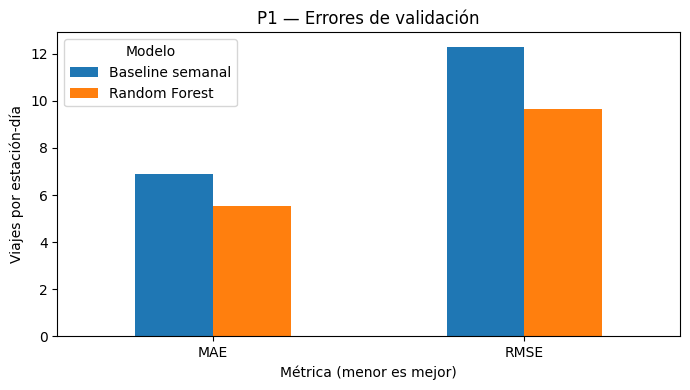

In [8]:
comparacion = pd.DataFrame({
  "Modelo": ["Baseline semanal", "Random Forest"],
  "MAE": [mae_baseline, mae_rf],
  "RMSE": [rmse_baseline, rmse_rf]
})
display(comparacion.round(4))

mejora_mae = 100 * (mae_baseline - mae_rf) / mae_baseline
mejora_rmse = 100 * (rmse_baseline - rmse_rf) / rmse_baseline
print(f"Reducción del MAE: {mejora_mae:.2f}%")
print(f"Reducción del RMSE: {mejora_rmse:.2f}%")

fig, ax = plt.subplots(figsize=(7, 4))
comparacion.set_index("Modelo")[["MAE", "RMSE"]].T.plot(kind="bar", ax=ax, rot=0)
ax.set_title("P1 — Errores de validación")
ax.set_ylabel("Viajes por estación-día")
ax.set_xlabel("Métrica (menor es mejor)")
ax.legend(title="Modelo")
plt.tight_layout()
plt.show()

## 9. Registro de experimentos en MLflow local

Se registran dos *runs* en `mibici-equipo37`: **P1 - Baseline semanal** y **P1 - Random Forest**. Cada run conserva el intervalo de fechas, tamaños de los conjuntos, configuración del modelo, métricas de validación, etiquetas del equipo y de Git y artefactos gráficos.

El almacenamiento es local: base de datos SQLite `mlflow.db` y artefactos en `mlruns/`. Estos archivos, el CSV y cualquier modelo serializado deben estar excluidos de Git. No se registran identificadores de usuarios, género ni año de nacimiento.

**Reproducción por terminal:** además de la ejecución exploratoria en Jupyter, `MiBici/modeling/train_p1.py` ejecuta el procesamiento, entrenamiento y registro de ambos runs con un comando. Para asociar las etiquetas `git_commit` a esta versión del código, haz el commit primero y ejecuta los experimentos después.

In [9]:
import hashlib
import subprocess
import warnings

# Evitar que la advertencia opcional de widgets publique rutas del entorno.
warnings.filterwarnings(
  "ignore",
  message=r"IProgress not found.*"
)

import mlflow

# Localizar y configurar el almacenamiento local de MLflow
tracking_db = project_root / "mlflow.db"
artifact_dir = project_root / "mlruns" / "mibici-equipo37"
artifact_dir.mkdir(parents=True, exist_ok=True)

mlflow.set_tracking_uri(f"sqlite:///{tracking_db.as_posix()}")
experiment_name = "mibici-equipo37"

if mlflow.get_experiment_by_name(experiment_name) is None:
  mlflow.create_experiment(
    experiment_name,
    artifact_location=artifact_dir.resolve().as_uri()
  )

mlflow.set_experiment(experiment_name)

# Identificar exactamente el archivo de datos sin publicar su contenido
hash_csv = hashlib.sha256()
with csv_path.open("rb") as archivo:
  for bloque in iter(lambda: archivo.read(8 * 1024 * 1024), b""):
    hash_csv.update(bloque)

data_sha256 = hash_csv.hexdigest()

# Identificador del último commit (repetir los runs después de confirmar el commit)
commit_result = subprocess.run(
  ["git", "-C", str(project_root), "rev-parse", "HEAD"],
  text=True,
  capture_output=True,
  check=False
)
git_commit = commit_result.stdout.strip() if commit_result.returncode == 0 else "sin-commit"

estado_git = subprocess.run(
  ["git", "-C", str(project_root), "status", "--porcelain", "--untracked-files=normal"],
  text=True,
  capture_output=True,
  check=False
)
git_worktree_clean = str(
  estado_git.returncode == 0 and not estado_git.stdout.strip()
).lower()

parametros_comunes = {
  "horizonte_dias": 1,
  "inicio_entrenamiento": str(train["fecha"].min().date()),
  "fin_entrenamiento": str(train["fecha"].max().date()),
  "inicio_validacion": str(val["fecha"].min().date()),
  "fin_validacion": str(val["fecha"].max().date()),
  "filas_entrenamiento": int(len(train)),
  "filas_validacion": int(len(val)),
  "dias_imputados": int(df_p1["sin_viajes_registrados"].sum()),
  "datos_sha256": data_sha256,
  "variable_objetivo": "viajes_iniciados"
}

etiquetas_comunes = {
  "equipo": "37",
  "pregunta": "P1",
  "git_commit": git_commit,
  "git_worktree_clean": git_worktree_clean,
  "version_datos": data_sha256,
  "conjunto_metricas": "validacion"
}

print("Experimento configurado:", experiment_name)
print("Versión del CSV (SHA-256, primeros 12 caracteres):", data_sha256[:12])
print("Commit actual:", git_commit[:12])

Experimento configurado: mibici-equipo37
Versión del CSV (SHA-256, primeros 12 caracteres): 2c3c293103cd
Commit actual: 9cd34a57a952


In [10]:
# Comparar visualmente las métricas con un artefacto seguro (sin viajes individuales)
fig_mlflow, ax_mlflow = plt.subplots(figsize=(8, 4))
comparacion.set_index("Modelo")[["MAE", "RMSE"]].T.plot(
  kind="bar",
  ax=ax_mlflow,
  rot=0
)
ax_mlflow.set_title("P1 — Comparación de modelos en validación")
ax_mlflow.set_ylabel("Error en viajes por estación-día")
ax_mlflow.set_xlabel("Métrica (menor es mejor)")
ax_mlflow.legend(title="Modelo")
fig_mlflow.tight_layout()

runs_p1 = [
  {
    "run_name": "P1 - Baseline semanal",
    "modelo": "baseline_semanal",
    "mae": float(mae_baseline),
    "rmse": float(rmse_baseline),
    "parametros": {"lag_dias": 7}
  },
  {
    "run_name": "P1 - Random Forest",
    "modelo": "random_forest_regressor",
    "mae": float(mae_rf),
    "rmse": float(rmse_rf),
    "parametros": {
      "n_estimators": 100,
      "max_depth": 18,
      "min_samples_leaf": 5,
      "random_state": 42
    }
  }
]

for informacion in runs_p1:
  with mlflow.start_run(run_name=informacion["run_name"]) as run:
    mlflow.log_params(parametros_comunes)
    mlflow.log_params(informacion["parametros"])
    mlflow.set_tags({
      **etiquetas_comunes,
      "modelo": informacion["modelo"]
    })
    mlflow.log_metrics({
      "val_mae": informacion["mae"],
      "val_rmse": informacion["rmse"]
    })
    mlflow.log_figure(fig_mlflow, "graficas/comparacion_p1.png")
    mlflow.log_dict({
      "modelo": informacion["modelo"],
      "mae_validacion": informacion["mae"],
      "rmse_validacion": informacion["rmse"],
      "nota": "Resultados sobre datos agregados por estacion y dia"
    }, "resumen_validacion.json")

    print(informacion["run_name"], "— run_id:", run.info.run_id)

plt.close(fig_mlflow)
print("Dos runs registrados en", experiment_name)


P1 - Baseline semanal — run_id: f0e544121fb14118967bb91f51e3a050
P1 - Random Forest — run_id: 0820761f31714168ab5d1c2abb7b4574
Dos runs registrados en mibici-equipo37


## 10. Conclusiones

**Resultados verificados:** 9,177,953 viajes; 24 meses; 731 días registrados; 373 IDs distintos de estaciones de origen; 265,105 combinaciones estación-día observadas; 768 días intermedios imputados como cero; 265,873 filas del panel y 263,262 observaciones con historial suficiente. En validación, Random Forest superó al baseline semanal en MAE y RMSE.

**Limitaciones del análisis:**

- Los 768 ceros imputados podrían representar estaciones cerradas o ausencia de registros. La operación histórica por estación no se identifica con estos campos del CSV.
- La cobertura de 731 días es global; no garantiza que cada estación operara todos esos días.
- Se predicen **viajes registrados**, no inventario de bicicletas ni demanda no atendida.
- El CSV de entrada se consolidó a partir de viajes mensuales; su descarga, normalización y versionado corresponden al flujo de ingesta común del proyecto.
- Las transformaciones compartidas del proyecto se integran en los módulos correspondientes durante la fase de integración del equipo.
- La comparación reportada se obtuvo en validación; el conjunto de prueba de octubre a diciembre de 2025 permaneció reservado.

**Privacidad:** el notebook puede compartirse sin incorporar el CSV, directorios personales, credenciales, identificadores de usuarios o modelos serializados. Las salidas conservadas contienen únicamente conteos agregados, métricas, identificadores de estación y visualizaciones del modelo.